# Hologramas sin iteración: hasta dónde llegan en un arreglo de trampas

**Pregunta:** ¿Hasta dónde llegan en un arreglo de 10 por 10 trampas los hologramas calculados en un solo paso, sin iteración, y qué limita a cada uno de los tres?

- **Nivel:** 1, Fundamentos
- **Requisitos previos:** los dos notebooks del tema 01
- **Tiempo de lectura:** unos 40 minutos

## Objetivos

Antes de cualquier iteración hay tres maneras de escribir un holograma para muchas trampas a la vez: sumar las redes y lentes de todas las trampas y conservar la fase de la suma, sumarlas con una fase aleatoria por trampa, o darle a cada trampa su propia parte aleatoria de los píxeles. Las tres son una sola pasada sobre los píxeles, y por eso fueron los primeros métodos y son la línea base de todos los posteriores. Ejecutarás los tres sobre las 100 trampas del caso C12, leerás su eficiencia, uniformidad y dispersión, y entenderás por los patrones de fase por qué cada uno cae donde cae: por qué la superposición descarta dos tercios de la luz, por qué las fases aleatorias cuestan uniformidad y por qué la máscara aleatoria conserva solo un uno por ciento.

## Preparación

El entorno de los notebooks está fijado en `notebooks/requirements.txt` y se construye con `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows). Los paquetes que usa este notebook, con sus versiones exactas:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot no publica ningún paquete propio: sus métodos viven en `data-pipeline/pipeline/` y el notebook los importa por su ruta. La celda siguiente importa las herramientas, imprime sus versiones y pone el pipeline en la ruta.

In [1]:
# las herramientas y sus versiones, luego los módulos del pipeline por su ruta
import importlib.metadata as md
import sys
import warnings
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore")
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases.build import setup_of, target_of
from pipeline.io.contract import read_cases
from pipeline.model.holo.core import geometry, metrics
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.traps import TrapSet
from pipeline.model.holo.core.types import Budget, Target
from pipeline.model.holo.methods.baseline import m01_superposition, m02_random_superposition, m03_random_mask

for name in ("numpy", "matplotlib"):
    print(name, md.version(name))


def array_numbers(res):
    """Eficiencia, uniformidad y dispersión relativa (por ciento) de los campos de trampa de un resultado."""
    i = metrics.trap_intensities(res.fields)
    return metrics.efficiency(i), metrics.uniformity(i), metrics.rel_std(i)

numpy 2.4.6
matplotlib 3.11.2


## Datos

- Propietario: este repositorio, https://github.com/fsantibanezleal/CEFOP_DinHot.
- Clase de licencia: caso sintético escrito por el producto, ningún conjunto de datos de terceros, cubierto por la licencia del repositorio.
- Archivo leído: `data/examples/cases.json`, caso C12, el arreglo de 10 por 10 del notebook anterior sobre un SLM de 256 por 256 píxeles, con cinco semillas contadas desde la semilla del caso.

In [2]:
# caso C12: el arreglo de 10 x 10 de la comparación publicada, en el SLM de 256 x 256 píxeles del producto
records = {rec["case_id"]: rec for rec in read_cases(ROOT / "data" / "examples" / "cases.json")}
rec = records["C12_calibration"]
setup = setup_of(rec)
target = target_of(rec)
traps = target.traps
budget = Budget(1)
seeds = [rec["seed"] + k for k in range(5)]
n_traps, n_pixels = len(traps), setup.n_pix**2
print(f"{n_traps} trampas, {n_pixels} píxeles del SLM, {n_pixels / n_traps:.0f} píxeles por trampa")

100 trampas, 65536 píxeles del SLM, 655 píxeles por trampa


## Método

Cada trampa $m$ pide la fase de red, lente y vórtice opcional $\Delta_j^m$ del notebook 01. Tres maneras de combinar los pedidos (Di Leonardo et al. 2007, Tabla 1, https://doi.org/10.1364/OE.15.001913). La superposición (M01) conserva la fase de la suma, $\phi_j = \arg\sum_m \sqrt{w_m}\,e^{i\Delta_j^m}$. La superposición aleatoria (M02) agrega una fase aleatoria $\theta_m$ por trampa, $\phi_j = \arg\sum_m \sqrt{w_m}\,e^{i(\Delta_j^m + \theta_m)}$. La máscara aleatoria (M03; Montes-Usategui et al. 2006, https://opg.optica.org/oe/fulltext.cfm?uri=oe-14-6-2101) reparte los píxeles en $M$ conjuntos aleatorios disjuntos de igual tamaño y deja que el píxel $j$ muestre solo la fase $\Delta_j^{m(j)}$ de la trampa que lo posee. Publicado para 10 por 10 con 768 por 768 píxeles: eficiencia 0,29, uniformidad 0,01 y dispersión 257 por ciento para la superposición; 0,69, 0,01 y 89 por ciento para la superposición aleatoria; 0,01, 0,58 y 16 por ciento para la máscara aleatoria. Las celdas siguientes ejecutan los tres, un método por celda.

Primero la superposición. No usa ningún número aleatorio, de modo que dos semillas distintas deben dar exactamente el mismo holograma, lo que la celda comprueba con la mayor diferencia de fase. También cuenta los valores de fase distintos del holograma, por una razón que la primera figura hace visible.

In [3]:
# la superposición no tiene azar: dos semillas distintas deben dar el mismo holograma
res_a = m01_superposition.run(setup, target, budget=budget, rng=Rng(1))
res_b = m01_superposition.run(setup, target, budget=budget, rng=Rng(2))
e, u, sigma = array_numbers(res_a)
print(f"M01: e = {e:.4f}, u = {u:.4f}, sigma = {sigma:.2f} %")
print(f"mayor diferencia de fase entre las dos semillas: {np.abs(res_a.phi - res_b.phi).max():.1e} rad")
levels = np.unique(np.mod(np.round(res_a.phi, 4), 2 * np.pi).round(4))
print(f"valores de fase distintos en el holograma: {len(levels)}: {levels}")

M01: e = 0.3280, u = 0.0003, sigma = 268.79 %
mayor diferencia de fase entre las dos semillas: 0.0e+00 rad
valores de fase distintos en el holograma: 2: [0.     3.1416]


La superposición aleatoria saca las fases de las trampas de la semilla. La celda ejecuta cinco semillas, imprime los tres números de cada una y su promedio, para que la variación de semilla a semilla se vea junto al promedio.

In [4]:
# superposición aleatoria: la misma suma con una fase aleatoria por trampa, cinco semillas
res_sr = [m02_random_superposition.run(setup, target, budget=budget, rng=Rng(s)) for s in seeds]
table_sr = np.array([array_numbers(r) for r in res_sr])
for s, (e, u, sigma) in zip(seeds, table_sr):
    print(f"M02 semilla {s}: e = {e:.4f}, u = {u:.4f}, sigma = {sigma:.2f} %")
m = table_sr.mean(axis=0)
print(f"promedio: e = {m[0]:.4f}, u = {m[1]:.4f}, sigma = {m[2]:.2f} %")

M02 semilla 20261028: e = 0.7485, u = 0.1994, sigma = 37.40 %
M02 semilla 20261029: e = 0.7395, u = 0.2017, sigma = 43.84 %
M02 semilla 20261030: e = 0.7203, u = 0.1477, sigma = 40.74 %
M02 semilla 20261031: e = 0.7532, u = 0.2626, sigma = 33.29 %
M02 semilla 20261032: e = 0.7366, u = 0.1907, sigma = 41.65 %
promedio: e = 0.7396, u = 0.2004, sigma = 39.38 %


La máscara aleatoria también depende de la semilla, a través de la partición de los píxeles. La celda ejecuta cinco semillas, imprime los números e informa cuántos píxeles posee cada trampa, que el método fija en una parte igual.

In [5]:
# máscara aleatoria: cada píxel sirve a una trampa, elegida al azar, cinco semillas
res_rm = [m03_random_mask.run(setup, target, budget=budget, rng=Rng(s)) for s in seeds]
table_rm = np.array([array_numbers(r) for r in res_rm])
for s, (e, u, sigma) in zip(seeds, table_rm):
    print(f"M03 semilla {s}: e = {e:.4f}, u = {u:.4f}, sigma = {sigma:.2f} %")
m = table_rm.mean(axis=0)
print(f"promedio: e = {m[0]:.4f}, u = {m[1]:.4f}, sigma = {m[2]:.2f} %")
share = np.bincount(res_rm[0].meta["owner"].ravel())
print(f"píxeles que posee una trampa, mínimo y máximo: {share.min()} a {share.max()}")
print(f"píxeles por trampa en un SLM de 768 por 768 con 100 trampas: {768 * 768 / 100:.0f}")

M03 semilla 20261028: e = 0.0099, u = 0.0768, sigma = 54.25 %
M03 semilla 20261029: e = 0.0104, u = 0.0620, sigma = 51.16 %
M03 semilla 20261030: e = 0.0100, u = 0.0497, sigma = 47.50 %
M03 semilla 20261031: e = 0.0100, u = 0.0523, sigma = 53.08 %
M03 semilla 20261032: e = 0.0099, u = 0.0463, sigma = 52.01 %
promedio: e = 0.0101, u = 0.0574, sigma = 51.60 %
píxeles que posee una trampa, mínimo y máximo: 655 a 656
píxeles por trampa en un SLM de 768 por 768 con 100 trampas: 5898


Dos de los números pueden predecirse. Una trampa que posee $N/M$ de los píxeles recibe la suma de esos píxeles, todos en fase con la trampa, de modo que $V_m \approx 1/M$ de la amplitud e $I_m \approx 1/M^2$, y la eficiencia sobre $M$ trampas es cerca de $1/M$. Los otros $N - N/M$ píxeles agregan a cada trampa una suma aleatoria cuya amplitud relativa a la señal es cerca de $M/\sqrt{N}$, y un error gaussiano complejo de ese tamaño relativo cambia la intensidad en cerca de $\sqrt{2}\,M/\sqrt{N}$ de desviación estándar relativa (un argumento de primer orden derivado para este notebook, no un resultado de las fuentes). La celda imprime ambas predicciones junto a las mediciones.

In [6]:
# las dos predicciones del texto: eficiencia 1/M y la dispersión de una suma con N / M píxeles alineados
e_pred = 1.0 / n_traps
sigma_pred = 100.0 * np.sqrt(2.0) * n_traps / np.sqrt(n_pixels)
print(f"eficiencia predicha {e_pred:.4f}, promedio medido {table_rm[:, 0].mean():.4f}")
print(f"dispersión predicha {sigma_pred:.1f} %, dispersión media medida {table_rm[:, 2].mean():.1f} %")

eficiencia predicha 0.0100, promedio medido 0.0101
dispersión predicha 55.2 %, dispersión media medida 51.6 %


La primera figura muestra los 48 por 48 píxeles centrales de un holograma de cada método, con la fase en la misma escala de color.

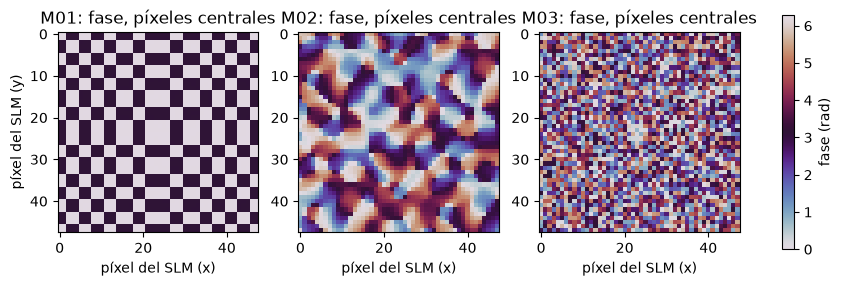

In [7]:
# los 48 x 48 píxeles centrales de un holograma de cada método
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
c = setup.n_pix // 2
shown = (("M01", res_a), ("M02", res_sr[0]), ("M03", res_rm[0]))
for ax, (name, res) in zip(axes, shown):
    im = ax.imshow(np.mod(res.phi, 2 * np.pi)[c - 24:c + 24, c - 24:c + 24], cmap="twilight", vmin=0, vmax=2 * np.pi)
    ax.set_title(f"{name}: fase, píxeles centrales")
    ax.set_xlabel("píxel del SLM (x)")
axes[0].set_ylabel("píxel del SLM (y)")
fig.colorbar(im, ax=axes, label="fase (rad)", shrink=0.8)
plt.show()

La superposición es un tablero de ajedrez de dos fases, 0 y $\pi$, como dijo el conteo de valores distintos: el arreglo es simétrico respecto del eje, así que la suma de sus redes es un número real y su fase solo puede ser 0 o $\pi$. Dos niveles de fase recuerdan el dispositivo de un bit del notebook 01, pero no son lo que retiene la eficiencia en 0,3280: en un arreglo simétrico el orden conjugado de cada trampa cae sobre otra trampa, así que la luz llega al arreglo de todos modos. La celda siguiente lo prueba moviendo el arreglo completo fuera del eje, lo que agrega una red global, no cambia nada en las intensidades de las trampas de un holograma perfecto y rompe la simetría que hace binaria la fase. La superposición aleatoria tiene parches suaves de todas las fases, porque las fases aleatorias de las trampas rompen la simetría y dejan que la suma tome cualquier valor. La máscara aleatoria es moteado a la escala de un píxel: los píxeles vecinos pertenecen a trampas distintas. La figura no muestra el plano focal; muestra solo por qué las tres fases se ven tan distintas.

La celda mueve el arreglo completo con dos desplazamientos de bins focales enteros, corre la superposición en cada uno e imprime su eficiencia, uniformidad y dispersión con el número de valores de fase distintos del holograma.

In [8]:
# el mismo arreglo movido fuera del eje: la fase ya no es binaria, ¿cambian los números?
bin_m = geometry.focal_bin_m(setup)
for dx, dy in ((0, 0), (3, 5), (20, 13)):
    moved = TrapSet(replace(t, x_m=t.x_m + dx * bin_m, y_m=t.y_m + dy * bin_m) for t in traps)
    res = m01_superposition.run(setup, Target.from_traps(moved), budget=budget, rng=Rng(1))
    e, u, sigma = array_numbers(res)
    n_levels = len(np.unique(np.mod(np.round(res.phi, 4), 2 * np.pi).round(4)))
    print(f"corrimiento ({dx:2d}, {dy:2d}) bins: e = {e:.4f}, u = {u:.4f}, sigma = {sigma:.2f} %, {n_levels} valores")


corrimiento ( 0,  0) bins: e = 0.3280, u = 0.0003, sigma = 268.79 %, 2 valores
corrimiento ( 3,  5) bins: e = 0.3280, u = 0.0003, sigma = 268.79 %, 512 valores
corrimiento (20, 13) bins: e = 0.3280, u = 0.0003, sigma = 268.79 %, 512 valores


La segunda figura ordena la potencia de las 100 trampas, relativa al promedio, para los tres métodos en un eje logarítmico.

M01: potencia relativa de 0.00 a 13.36 veces el promedio
M02: potencia relativa de 0.24 a 2.14 veces el promedio
M03: potencia relativa de 0.15 a 3.76 veces el promedio


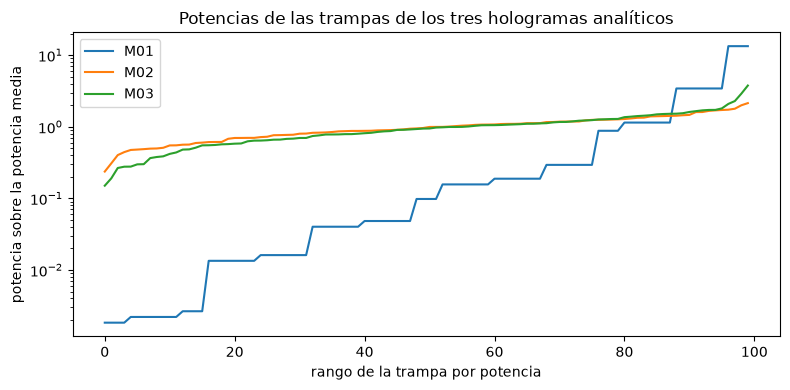

In [9]:
# la potencia de cada trampa relativa al promedio, ordenada, para los tres métodos
fig, ax = plt.subplots(figsize=(8, 4))
for name, res in shown:
    i = metrics.trap_intensities(res.fields)
    ax.semilogy(np.sort(i / i.mean()), label=name)
    print(f"{name}: potencia relativa de {(i / i.mean()).min():.2f} a {(i / i.mean()).max():.2f} veces el promedio")
ax.set_xlabel("rango de la trampa por potencia")
ax.set_ylabel("potencia sobre la potencia media")
ax.set_title("Potencias de las trampas de los tres hologramas analíticos")
ax.legend()
fig.tight_layout()
plt.show()

La superposición abarca más de tres órdenes de magnitud, en escalones planos fijados por la simetría de la red. La superposición aleatoria abarca cerca de una década, de unas 0,24 a 2,1 veces el promedio, y la máscara aleatoria algo más, de unas 0,15 a 3,8 (los rangos exactos están impresos arriba); su dispersión viene del mismo tipo de suma aleatoria. La figura compara potencias relativas, de modo que oculta la escala absoluta en que más difieren, pues la máscara aleatoria pone cerca de un uno por ciento de la potencia de entrada en las trampas mientras la superposición aleatoria pone cerca de tres cuartos. Un holograma con elementos aleatorios reparte las potencias de forma pareja en la imagen logarítmica pero no las iguala, y las iteraciones de los notebooks siguientes son la manera de igualarlas.

## Resultados

**Respuesta:** Sin iteración los tres hologramas llegan a lugares muy distintos en las 100 trampas de C12. La superposición es determinista, con eficiencia 0,3280, uniformidad 0,0003 y una dispersión de 268,79 por ciento; su fase tiene solo dos valores porque el arreglo es simétrico respecto del eje, y el mismo arreglo movido fuera del eje tiene una fase de cientos de niveles y la misma eficiencia y dispersión, de modo que los números bajos son de la superposición y no de la fase binaria. La superposición aleatoria obtiene una eficiencia de 0,7396 en promedio, sobre el 0,69 publicado, con una uniformidad de 0,2004 y una dispersión de 39,38 por ciento donde los valores publicados son 0,01 y 89 por ciento: en esta grilla el método es más uniforme de lo que informa el artículo, y el notebook siguiente pregunta por qué. La máscara aleatoria conserva 0,0101 de la luz, que coincide con la predicción de 1/M = 0,0100, con una uniformidad de 0,0574 y una dispersión de 51,60 por ciento, frente a 55,2 por ciento predicho con 655 píxeles por trampa; la uniformidad de 0,58 y la dispersión de 16 por ciento publicadas para la máscara aleatoria son para 5898 píxeles por trampa (768 por 768 píxeles, impreso arriba), y el notebook siguiente las alcanza en esa grilla. Ninguno es un holograma para un experimento: el mejor, la superposición aleatoria, deja un cuarto de la luz fuera de las trampas y sus trampas difieren en potencia por un factor cercano a diez, y para eso están las iteraciones.

## Resumen

Los hologramas de un paso son rápidos y llevan una firma. La superposición tiene la mayor dispersión de potencias y, para un arreglo simétrico, una fase binaria; la superposición aleatoria recupera la eficiencia a costa de la uniformidad; la máscara aleatoria tiene una eficiencia fijada cerca de uno sobre el número de trampas y una dispersión que baja cuando crecen los píxeles por trampa. El notebook siguiente mide esa dependencia con el número de píxeles y compara los tres con la tabla publicada de 10 por 10.

## Referencias

- Di Leonardo, Ianni y Ruocco, "Computer generation of optimal holograms for optical trap arrays", Optics Express 15, 1913 (2007), https://doi.org/10.1364/OE.15.001913.
- Montes-Usategui, Pleguezuelos, Andilla y Martin-Badosa, "Fast generation of holographic optical tweezers by random mask encoding of Fourier components", Optics Express 14, 2101 (2006), https://opg.optica.org/oe/fulltext.cfm?uri=oe-14-6-2101.